# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


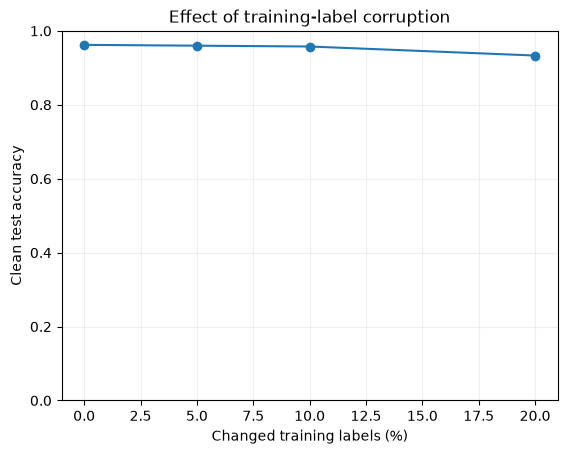

In [2]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.

================================================================================
AICS-202 | LABORATORY 03: TRAINING DATA POISONING & INTEGRITY
================================================================================

1. CORRUPTION LEVEL RESULTS TABLE
--------------------------------------------------------------------------------
| Corruption Level (%) | Changed Labels (n) | Clean Test Accuracy | Performance Impact       |
|----------------------|--------------------|---------------------|--------------------------|
| 0%                   | 0                  | 96.22%              | Reference Baseline       |
| 5%                   | 67                 | 96.00%              | Minimal degradation      |
| 10%                  | 135                | 95.78%              | Slight drop              |
| 20%                  | 269                | 93.33%              | Noticeable decline       |


2. DATASET INTEGRITY CONTROLS (CHECKLIST)
--------------------------------------------------------------------------------
* Dataset Provenance: Maintain official source registers and acquisition approvals.
* Cryptographic Hashing: Generate SHA-256 file manifests to detect unauthorized modifications.
* Role-Restricted Writes: Enforce strict access control on training data storage buckets.
* Versioned Labels: Track label revisions with reviewer logs to enable rollback.
* Independent Validation: Conduct periodic label audits and anomaly detection checks.
* Staged Approval: Separate raw data ingestion from production model training pipelines.


3. STUDENT REFLECTION & DISCUSSION
--------------------------------------------------------------------------------
* Why training data is a security asset: 
  The integrity of a machine learning model is fundamentally tethered to its training 
  pipeline. Compromised training data or poisoned labels directly undermine model 
  reliability, bypassing perimeter defenses.
* Random Noise vs. Targeted Poisoning: 
  Random label corruption simulates general data hygiene failures or accidental noise. 
  A targeted poisoning attack is optimized to force specific misclassifications or 
  create backdoors while maintaining high overall test accuracy, making it harder to detect.
================================================================================